# Lab 08: Graphs, latent variables, and what the survey didn't keep

**ASTR 457, Fall 2026, posted Thu Oct 29, due Wed Nov 4 by noon (fork → PR, as always)**

This week we wrote graphs as `PyMC` code, and put a detector into the likelihood. You're going to do both, on your own midterm supernovae, on a survey that rejects everything below a threshold, and on one real Type Ia supernova observed in six bands.

Put your notebook in `submissions/<your netid>/lab08.ipynb` - the data paths below are relative to that folder. It has to run top to bottom from a fresh kernel ("Restart & Run All").

Part 1 is 35%, Part 2 30%, Part 3 25%, and the AI-use appendix and verification plan 10%. Quote every number with its unit (if it has one), an error bar, and a sensible number of digits.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize
import pymc as pm
import pytensor.tensor as pt
import arviz as az

NETID = 'anuvacg2'   # <-- set this
curLAB = f'data/{NETID}.csv' 
LAB = '../../labs/08/data/'                              # from submissions/<your netid>/
MIDTERM = f'../../labs/midterm/data/{NETID}/'

d = np.genfromtxt(curLAB, delimiter=',', names=True)
cnts = d['n_counts']
df = pd.DataFrame({"counts": cnts})
print(df["counts"].describe())

count    1500.000000
mean      486.922667
std       826.014860
min        33.000000
25%        65.000000
50%       142.500000
75%       454.250000
max      3500.000000
Name: counts, dtype: float64


## Part 1: Your midterm, as a graph (35%)

On the midterm you fit the Tripp relation to your 250 supernovae (`p2_pantheon_sne.csv` in your midterm data folder):

$$m_B = M + \mu(z) - \alpha\,x_1 + \beta\,c + \gamma\,\Theta(\log M_\star - 10).$$

In the posted solution's 2e simulation, the 68% interval on $\beta$ contained the true $\beta$ in only **6%** of 200 fake datasets! The other four parameters covered the truth 62-66% of the time. The solution blamed attenuation. You're going to draw the graph that shows where it comes from, build the model that removes it, and check that it does.

1. Draw the probabilistic graphical model of your midterm fit (your 2b likelihood), using the same key as Day 18 - parameters you fit as blue circles, latent (unobserved) values as white circles, data as grey circles, fixed quantities as dots, and a plate over supernovae. Draw it by hand (a photo is fine) or with any drawing tool, and put the image in your notebook. Then draw the graph of how the data were actually made. Each supernova has a *true* stretch $x_{1,i}$ and a *true* color $c_i$, drawn from a population (a mean and a width for each), and the catalog's $\hat m_{B,i}$, $\hat x_{1,i}$, $\hat c_i$ are noisy measurements of the true values, with that supernova's $3\times3$ covariance $C_i$. Which arrows does the midterm's graph lack, and which circle did it shade grey that should be white?
2. Fit the second graph in `PyMC`, with latent `x1_true` and `c_true` (one per supernova, `shape=N`), a mean and a width for each population, and the three observed quantities together in a `pm.MvNormal` with each $C_i$. Add $\sigma_{\rm int}^2$ and the peculiar-velocity variance to the $m_B$ term only. Handle the contaminants as you did on the midterm, and explain how. Pick centered or non-centered by Day 19's rule (compare the measurement errors with the population widths), and justify your choice. Report the largest $\hat R$, the smallest bulk effective sample size (the latent values included) and the number of divergences, then $\alpha$, $\beta$, $\gamma$ and $\sigma_{\rm int}$ as medians with 68% intervals, in a table next to your midterm values.
3. Rerun the solution's 2e simulation at your own stretches, colors and covariances, with at least 20 fake datasets and true $\beta = 2.9$ (the other true values are in the solution, which uses your catalog $x_1$ and $c$ as the true ones). Fit each with your midterm model and with the latent model, and report the mean $\hat\beta$ for each model with its standard error (the scatter over datasets divided by $\sqrt{N_{\rm sim}}$). Then explain, in a few sentences, why using the measured $x_1$ and $c$ as the regressors, with their errors only in the variance (as the midterm did), biases $\beta$ toward zero, why the latent model doesn't, and why $\beta$ is biased more than $\alpha$. Think particularly about $c$'s errors compared with the spread of $c$, and $x_1$'s errors compared with the spread of $x_1$.

#### Hints:
- You don't need to sample each fake dataset in 1.3. Everything here is Gaussian, so you can integrate the true $x_1$ and $c$ out on paper - each supernova's observed $(\hat m_B, \hat x_1, \hat c)$ is then Gaussian, with a mean and covariance that depend only on the parameters and the two populations. Write them down, maximize that likelihood, and check its answer on your real data against your `PyMC` fit.
- **Don't use `pm.find_MAP` on the 1.2 model.** Its peak over all the latent values at once is degenerate (the population width collapses), and you'll get a wrong $\beta$ that looks reasonable.

removed 3 of 250: index [ 11  40 224]


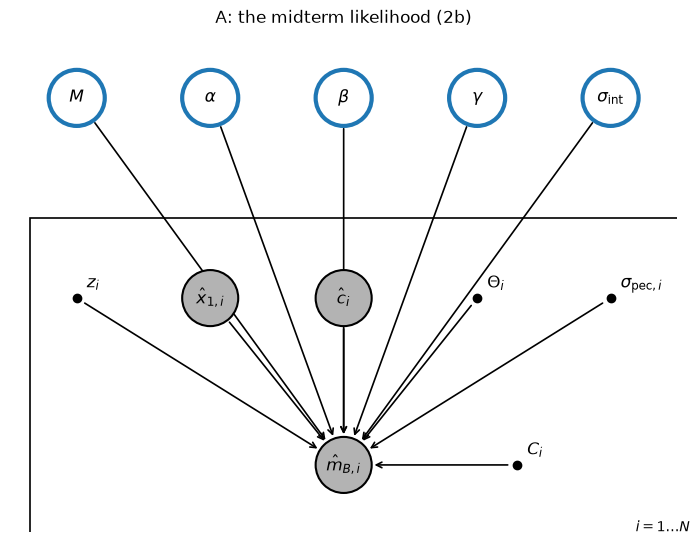

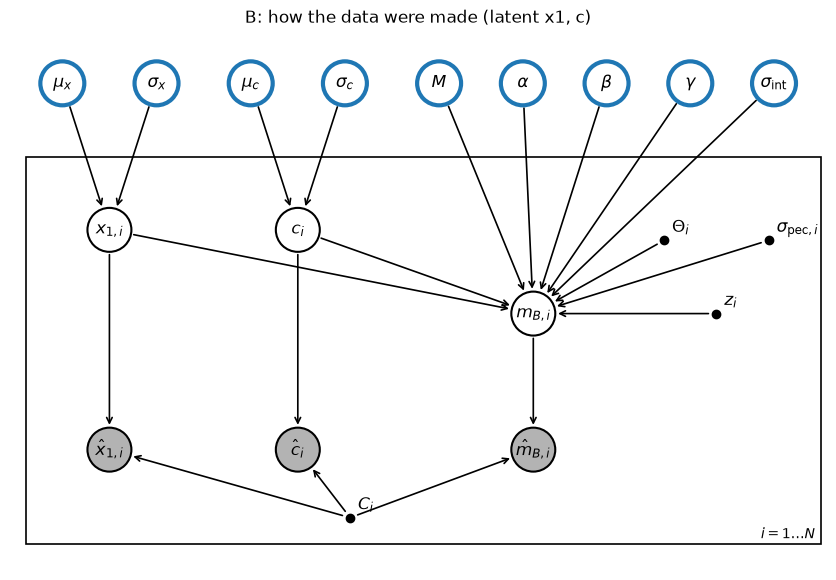

In [2]:
# Part 1: your work here

from astropy.cosmology import FlatLambdaCDM
from scipy.optimize import brentq
from matplotlib.patches import Circle, Rectangle

# reused from midterm: 
def load(name): return pd.read_csv(MIDTERM + name + '.csv', dtype={'name': str})
def fmt(v, e, unit=''):
    d = 1 - int(np.floor(np.log10(abs(e))))
    return f"{round(v, d):.{max(d, 0)}f} ± {round(e, d):.{max(d, 0)}f} {unit}".strip()
def fmt_asym(v, lo, hi, unit=''):
    d = 1 - int(np.floor(np.log10(min(lo, hi))))
    f = lambda x: f"{round(x, d):.{max(d, 0)}f}"
    return f"{f(v)} +{f(hi)} / -{f(lo)} {unit}".strip()

sn = load('p2_pantheon_sne')
z_sn, mB = sn['z'].to_numpy(), sn['mB'].to_numpy()
x1, col, logM = sn['x1'].to_numpy(), sn['c'].to_numpy(), sn['host_logmass'].to_numpy()
mu_z = FlatLambdaCDM(H0=70, Om0=0.3).distmod(z_sn).value
resid, Theta = mB - mu_z, (logM > 10).astype(float)
pec2 = (5 / np.log(10) * 250.0 / (299792.458 * z_sn))**2
D_all = dict(y=resid, x1=x1, col=col, Th=Theta,
             vmB=sn['mB_err'].to_numpy()**2, vx1=sn['x1_err'].to_numpy()**2, vc=sn['c_err'].to_numpy()**2,
             cmx=sn['cov_mB_x1'].to_numpy(), cmc=sn['cov_mB_c'].to_numpy(), cxc=sn['cov_x1_c'].to_numpy(), pec2=pec2)

def sigma2(th, D):
    M, a, b, g, lns = th
    return (D['vmB'] + a**2*D['vx1'] + b**2*D['vc'] + 2*a*D['cmx'] - 2*b*D['cmc'] - 2*a*b*D['cxc']
            + D['pec2'] + np.exp(2*lns))
def loglike(th, D):
    M, a, b, g, lns = th
    r = D['y'] - M + a*D['x1'] - b*D['col'] - g*D['Th']; s2 = sigma2(th, D)
    return -0.5*np.sum(r**2/s2 + np.log(2*np.pi*s2))
GSD = 0.1
def logpost1(th, D, gsd=GSD):
    M, a, b, g, lns = th
    if not ((-21 < M < -17) and (-1 < a < 1) and (0 < b < 8) and (np.log(1e-3) < lns < 0)): return -np.inf
    return -0.5*(g/gsd)**2 + loglike(th, D) 
H5 = np.array([1e-3, 1e-3, 1e-2, 2e-3, 5e-3])
def num_hess(f, x, h):
    n_ = len(x); E = np.diag(h); H = np.zeros((n_, n_))
    for i in range(n_):
        for j in range(n_):
            H[i, j] = (f(x+E[i]+E[j]) - f(x+E[i]-E[j]) - f(x-E[i]+E[j]) + f(x-E[i]-E[j])) / (4*h[i]*h[j])
    return H
def maximize(logf, th0, h):
    def nlf(th):
        v = logf(th); return -v if np.isfinite(v) else 1e30
    opt = dict(xatol=1e-9, fatol=1e-10, maxiter=20000, maxfev=20000, adaptive=True)
    x = np.array(th0, float)
    for _ in range(3): x = minimize(nlf, x, method='Nelder-Mead', options=opt).x
    return x, -nlf(x), np.linalg.inv(num_hess(nlf, x, h))
def start(D):
    A = np.column_stack([np.ones_like(D['y']), D['x1'], D['col'], D['Th']])
    cf = np.linalg.lstsq(A, D['y'], rcond=None)[0]
    return np.array([cf[0], -cf[1], cf[2], cf[3], np.log(max(0.5*np.std(D['y'] - A@cf), 0.02))])
def sub(D, keep): return {k: v[keep] for k, v in D.items()}
def std_resid(th, D):
    M, a, b, g, lns = th
    return (D['y'] - M + a*D['x1'] - b*D['col'] - g*D['Th']) / np.sqrt(sigma2(th, D))
def clip_fit(D, K=4.0, max_iter=20):
    keep = np.ones(len(D['y']), bool)
    for _ in range(max_iter):
        Dk = sub(D, keep)
        th, _, _ = maximize(lambda t: logpost1(t, Dk), start(Dk), H5)
        zr = std_resid(th, D); new_keep = zr < K 
        if np.array_equal(new_keep, keep): break
        keep = new_keep
    return keep, th, zr
keep, th_cut, zr = clip_fit(D_all, 4.0)
D = sub(D_all, keep); N = len(D['y'])
print(f"removed {(~keep).sum()} of {len(keep)}: index {np.where(~keep)[0]}")

Cn = np.empty((N, 3, 3))
Cn[:, 0, 0], Cn[:, 1, 1], Cn[:, 2, 2] = D['vmB'], D['vx1'], D['vc']
Cn[:, 0, 1] = Cn[:, 1, 0] = D['cmx']; Cn[:, 0, 2] = Cn[:, 2, 0] = D['cmc']; Cn[:, 1, 2] = Cn[:, 2, 1] = D['cxc']

# 1.1 
RAD = {'fixed': 0.1, 'param': 0.42, 'latent': 0.42, 'data': 0.42}
def draw_pgm(nodes, edges, plate, title, size=(12, 6.5)):
    fig, ax = plt.subplots(figsize=size)
    for k, (x, y, lab, kind) in nodes.items():
        if kind == 'fixed':
            ax.plot(x, y, 'ko', ms=6); ax.text(x + 0.15, y + 0.15, lab, fontsize=12)
        else:
            ax.add_patch(Circle((x, y), RAD[kind], fc='0.7' if kind == 'data' else 'w',
                                ec='tab:blue' if kind == 'param' else 'k', lw=3 if kind == 'param' else 1.5, zorder=2))
            ax.text(x, y, lab, ha='center', va='center', fontsize=12, zorder=3)
    for a, b in edges:
        (xa, ya, _, ka), (xb, yb, _, kb) = nodes[a], nodes[b]; L = np.hypot(xb - xa, yb - ya)
        ax.annotate('', xy=(xb - (xb - xa)*RAD[kb]/L, yb - (yb - ya)*RAD[kb]/L),
                    xytext=(xa + (xb - xa)*RAD[ka]/L, ya + (yb - ya)*RAD[ka]/L),
                    arrowprops=dict(arrowstyle='->', lw=1.2), zorder=1)
    x0, y0, w, h, lab = plate
    ax.add_patch(Rectangle((x0, y0), w, h, fill=False, lw=1.2)); ax.text(x0 + w - 0.1, y0 + 0.1, lab, ha='right')
    xs = [v[0] for v in nodes.values()]; ys = [v[1] for v in nodes.values()]
    ax.set_xlim(min(xs) - 1, max(xs) + 1); ax.set_ylim(min(ys) - 1, max(ys) + 1)
    ax.set_aspect('equal'); ax.axis('off'); ax.set_title(title); plt.show()

nodesA = {'M': (1, 7, r'$M$', 'param'), 'a': (3, 7, r'$\alpha$', 'param'), 'b': (5, 7, r'$\beta$', 'param'),
          'g': (7, 7, r'$\gamma$', 'param'), 's': (9, 7, r'$\sigma_{\rm int}$', 'param'),
          'x': (3, 4, r'$\hat x_{1,i}$', 'data'), 'c': (5, 4, r'$\hat c_i$', 'data'),
          'zz': (1, 4, r'$z_i$', 'fixed'), 'T': (7, 4, r'$\Theta_i$', 'fixed'), 'P': (9, 4, r'$\sigma_{{\rm pec},i}$', 'fixed'),
          'mB': (5, 1.5, r'$\hat m_{B,i}$', 'data'), 'C': (7.6, 1.5, r'$C_i$', 'fixed')}
edgesA = [(k, 'mB') for k in ['M', 'a', 'b', 'g', 's', 'x', 'c', 'zz', 'T', 'P', 'C']]
draw_pgm(nodesA, edgesA, (0.3, 0.4, 10.0, 4.8, r'$i=1\ldots N$'), 'A: the midterm likelihood (2b)')

nodesB = {'mx': (1, 9, r'$\mu_x$', 'param'), 'sx': (2.8, 9, r'$\sigma_x$', 'param'),
          'mc': (4.6, 9, r'$\mu_c$', 'param'), 'sc': (6.4, 9, r'$\sigma_c$', 'param'),
          'M': (8.2, 9, r'$M$', 'param'), 'a': (9.8, 9, r'$\alpha$', 'param'), 'b': (11.4, 9, r'$\beta$', 'param'),
          'g': (13, 9, r'$\gamma$', 'param'), 's': (14.6, 9, r'$\sigma_{\rm int}$', 'param'),
          'x1t': (1.9, 6.2, r'$x_{1,i}$', 'latent'), 'ct': (5.5, 6.2, r'$c_i$', 'latent'),
          'mt': (10, 4.6, r'$m_{B,i}$', 'latent'),
          'T': (12.5, 6, r'$\Theta_i$', 'fixed'), 'zz': (13.5, 4.6, r'$z_i$', 'fixed'), 'P': (14.5, 6, r'$\sigma_{{\rm pec},i}$', 'fixed'),
          'xh': (1.9, 2, r'$\hat x_{1,i}$', 'data'), 'ch': (5.5, 2, r'$\hat c_i$', 'data'), 'mh': (10, 2, r'$\hat m_{B,i}$', 'data'),
          'C': (6.5, 0.7, r'$C_i$', 'fixed')}
edgesB = ([('mx', 'x1t'), ('sx', 'x1t'), ('mc', 'ct'), ('sc', 'ct'), ('x1t', 'mt'), ('ct', 'mt'), ('x1t', 'xh'), ('ct', 'ch'),
           ('mt', 'mh'), ('C', 'xh'), ('C', 'ch'), ('C', 'mh')] + [(k, 'mt') for k in ['M', 'a', 'b', 'g', 's', 'T', 'zz', 'P']])
draw_pgm(nodesB, edgesB, (0.3, 0.2, 15.2, 7.4, r'$i=1\ldots N$'), 'B: how the data were made (latent x1, c)', size=(14, 7))

In [3]:
# 1.2 -- this cell takes about 7 minutes 
import warnings
warnings.filterwarnings('ignore', message='.*OpenMP.*', category=RuntimeWarning)
import pymc as pm, pytensor.tensor as pt

sx_pop = np.sqrt(max(np.var(D['x1']) - np.mean(D['vx1']), 1e-6)); sc_pop = np.sqrt(max(np.var(D['col']) - np.mean(D['vc']), 1e-6))
print(f"x1: median error {np.median(np.sqrt(D['vx1'])):.3f} vs population width {sx_pop:.3f};  "
      f"c: median error {np.median(np.sqrt(D['vc'])):.3f} vs population width {sc_pop:.3f}")
CENTERED = (np.median(np.sqrt(D['vx1'])) < sx_pop) and (np.median(np.sqrt(D['vc'])) < sc_pop)
print('centered' if CENTERED else 'non-centered')

obs = np.column_stack([D['y'], D['x1'], D['col']]) 
E00 = np.zeros((3, 3)); E00[0, 0] = 1.0
with pm.Model() as latent_model:
    M = pm.Uniform('M', -21, -17); alpha = pm.Uniform('alpha', -1, 1); beta = pm.Uniform('beta', 0, 8)
    gamma = pm.Normal('gamma', 0, 0.1)
    ln_sint = pm.Uniform('ln_sigma_int', np.log(1e-3), 0.0)
    sigma_int = pm.Deterministic('sigma_int', pt.exp(ln_sint))
    mu_x, sig_x = pm.Normal('mu_x', 0, 2), pm.HalfNormal('sig_x', 2)
    mu_c, sig_c = pm.Normal('mu_c', 0, 0.5), pm.HalfNormal('sig_c', 0.5)
    if CENTERED:
        x1_true = pm.Normal('x1_true', mu_x, sig_x, shape=N)
        c_true = pm.Normal('c_true', mu_c, sig_c, shape=N)
    else:
        eta_x, eta_c = pm.Normal('eta_x', 0, 1, shape=N), pm.Normal('eta_c', 0, 1, shape=N)
        x1_true = pm.Deterministic('x1_true', mu_x + sig_x*eta_x); c_true = pm.Deterministic('c_true', mu_c + sig_c*eta_c)
    mean_y = M - alpha*x1_true + beta*c_true + gamma*D['Th']
    mean = pt.stack([mean_y, x1_true, c_true], axis=1)
    cov = Cn + (sigma_int**2 + D['pec2'])[:, None, None]*E00
    pm.MvNormal('obs', mu=mean, cov=cov, observed=obs)
    idata = pm.sample(1000, tune=1500, chains=4, target_accept=0.9, random_seed=457, progressbar=False, blas_cores=None)
allv = ['M', 'alpha', 'beta', 'gamma', 'sigma_int', 'mu_x', 'sig_x', 'mu_c', 'sig_c', 'x1_true', 'c_true']
summ = az.summary(idata, var_names=allv)
print(f"max R-hat = {summ['r_hat'].max():.3f};  min bulk ESS = {summ['ess_bulk'].min():.0f};  "
      f"divergences = {int(idata.sample_stats['diverging'].values.sum())}")

post = lambda k: np.asarray(idata.posterior[k]).ravel()
def row(k, unit):
    lo, md, hi = np.percentile(post(k), [16, 50, 84]);

x1: median error 0.168 vs population width 0.967;  c: median error 0.034 vs population width 0.085
centered


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [M, alpha, beta, gamma, ln_sigma_int, mu_x, sig_x, mu_c, sig_c, x1_true, c_true]
Sampling 4 chains for 1_500 tune and 1_000 draw iterations (6_000 + 4_000 draws total) took 190 seconds.


max R-hat = 1.007;  min bulk ESS = 2336;  divergences = 0


In [4]:
# 1.3
def nll_latent(p, y, x, c, Th, Cn, pec2):
    M, a, b, g, lns, mx, lsx, mc, lsc = p
    A = np.array([[-a, b], [1.0, 0.0], [0.0, 1.0]])
    S_ = Cn + (np.exp(2*lns) + pec2)[:, None, None]*E00 + (A*[np.exp(2*lsx), np.exp(2*lsc)]) @ A.T
    r = np.stack([y - (M - a*mx + b*mc + g*Th), x - mx, c - mc], axis=1)
    sol = np.linalg.solve(S_, r[:, :, None])[:, :, 0]
    return 0.5*np.sum(np.einsum('ni,ni->n', r, sol) + np.linalg.slogdet(S_)[1])
def fit_latent(y, x, c, Th, pec2, p0):
    f = lambda p: nll_latent(p, y, x, c, Th, Cn, pec2)
    r = minimize(f, p0, method='BFGS')
    return minimize(f, r.x, method='Nelder-Mead', options=dict(xatol=1e-8, fatol=1e-10, maxiter=40000, maxfev=40000, adaptive=True)).x
mom = lambda x, c: [x.mean(), np.log(x.std()), c.mean(), np.log(c.std())]

# check against PyMC on the real data
p_real = fit_latent(D['y'], D['x1'], D['col'], D['Th'], D['pec2'], np.r_[th_cut, mom(D['x1'], D['col'])])
print("analytic ML : alpha %.4f beta %.3f gamma %.4f sigma_int %.4f" % (p_real[1], p_real[2], p_real[3], np.exp(p_real[4])))
print("PyMC medians: alpha %.4f beta %.3f gamma %.4f sigma_int %.4f" % tuple(np.median(post(k)) for k in ['alpha', 'beta', 'gamma', 'sigma_int']))

truth = np.array([-19.3, 0.15, 2.9, -0.06, np.log(0.10)]) 
Lc = np.linalg.cholesky(Cn); N_SIM = 40; rng = np.random.default_rng(808)
def simulate_obs(rng):
    M_, a_, b_, g_, lns_ = truth
    e = np.einsum('nij,nj->ni', Lc, rng.normal(size=(N, 3))) 
    y_o = M_ - a_*D['x1'] + b_*D['col'] + g_*D['Th'] + e[:, 0] + rng.normal(0, np.sqrt(D['pec2'] + np.exp(2*lns_)))
    return y_o, D['x1'] + e[:, 1], D['col'] + e[:, 2]
est = []
for s in range(N_SIM):
    y_o, x_o, c_o = simulate_obs(rng); Ds = dict(D, y=y_o, x1=x_o, col=c_o)
    t = start(Ds)
    for _ in range(3): 
        t = minimize(lambda q: -loglike(q, Ds), t, method='Nelder-Mead',
                     options=dict(xatol=1e-9, fatol=1e-10, maxiter=20000, maxfev=20000, adaptive=True)).x
    p = fit_latent(y_o, x_o, c_o, D['Th'], D['pec2'], np.r_[t, mom(x_o, c_o)])
    est.append([t[1], t[2], p[1], p[2]])
est = np.array(est); m_, se_ = est.mean(0), est.std(0, ddof=1)/np.sqrt(N_SIM)
for lab, i, tv, u in [('alpha', 0, truth[1], 'mag'), ('beta', 1, truth[2], '')]:
    print(f"{lab} (true {tv}): midterm model {fmt(m_[i], se_[i], u)};  latent model {fmt(m_[i+2], se_[i+2], u)}")
lam_c = np.var(D['col'])/(np.var(D['col']) + np.mean(D['vc'])); lam_x = np.var(D['x1'])/(np.var(D['x1']) + np.mean(D['vx1']))
print(f"attenuation factors: lambda_c = {lam_c:.3f}, lambda_x = {lam_x:.3f}")

analytic ML : alpha 0.1537 beta 3.014 gamma -0.0358 sigma_int 0.1099
PyMC medians: alpha 0.1535 beta 3.015 gamma -0.0342 sigma_int 0.1112
alpha (true 0.15): midterm model 0.1422 ± 0.0014 mag;  latent model 0.1499 ± 0.0014 mag
beta (true 2.9): midterm model 2.682 ± 0.016;  latent model 2.889 ± 0.019
attenuation factors: lambda_c = 0.859, lambda_x = 0.937


In [5]:
def row(k, unit):
    lo, md, hi = np.percentile(post(k), [16, 50, 84]); return fmt_asym(md, md - lo, hi - md, unit)
midterm = {'alpha': '0.1451 +0.0095 / -0.0097 mag', 'beta': '2.76 +0.10 / -0.10',
           'gamma': '-0.033 +0.019 / -0.019 mag', 'sigma_int': '0.1145 +0.0087 / -0.0085 mag'}
print(pd.DataFrame({'midterm (measured x1, c)': midterm,
                    'latent model': {k: row(k, u) for k, u in [('alpha', 'mag'), ('beta', ''), ('gamma', 'mag'), ('sigma_int', 'mag')]}}))

               midterm (measured x1, c)                  latent model
alpha      0.1451 +0.0095 / -0.0097 mag  0.1535 +0.0097 / -0.0100 mag
beta                 2.76 +0.10 / -0.10            3.01 +0.12 / -0.12
gamma        -0.033 +0.019 / -0.019 mag    -0.034 +0.019 / -0.019 mag
sigma_int  0.1145 +0.0087 / -0.0085 mag  0.1112 +0.0087 / -0.0085 mag


**ANSWER (the two graphs, the table, the simulation result, then the explanation):**
\
The midterm graph lacks the arrows from the population parameters (μₓ, σₓ, μ_c, σ_c) to the true x₁,ᵢ and cᵢ, and from the true values to the measured x̂₁,ᵢ and ĉᵢ (with Cᵢ). It also shaded x̂₁ and ĉ grey as exact regressors when the true x₁,ᵢ and cᵢ should be the white circles feeding m_B. Additonally, this model shifts β from 2.76 ± 0.10 to 3.01 ± 0.12 and α from 0.1451 ± 0.0097 to 0.1535 ± 0.0099 mag  while keeping γ and σ_int stable, which is consistent with measurement error in x₁ and c
\
Using the measured $\hat{x}_1$ and $\hat{c}$ as regressors makes each correlated with its own measurement error so the fitted slope shrinks toward zero by roughly because of the correlated residuals. Adding the errors to the variance only widens the error bars, leaving the correlation untouched. This model regresses on the true x1 and c, which treats $\hat{x}_1$ and $\hat{c}$ as noisy measurements and lets the population width say how much of the spread is real. This allows it to recover the input in simulation β is more biased than α because c’s errors are a larger fraction of its spread than x1’s. The same shift appears on the real data, where the correction moves β from 2.76 to 3.01 and α from 0.145 to 0.154.

## Part 2: What the survey didn't keep (30%)

We'll use a simplified model of photon-counting aperture photometry. A source with true flux $F$ (in units of a reference flux $F_0$) gives, on average, $\epsilon F + \nu$ counts - $\epsilon = 226.27$ counts per $F_0$ is the exposure, and $\nu = 9.373$ counts is the background (sky plus detector) that lands in the aperture with or without a source. The survey keeps a source only if it counts $n > 32$ photons (about a 4$\sigma$ detection) - anything fainter never makes it into the catalog.

The true fluxes come from a **lognormal** population, $\ln F \sim \mathcal{N}(\mu, \sigma)$. Your catalog, `08/data/<your netid>.csv`, has one column, `n_counts`, for the first 1500 sources the survey detected. I generated it, so I know your $\mu$ and $\sigma$, and how many sources the survey missed. Your $\mu$ and $\sigma$ are graded by how far they are from the truth in units of your own error bars.

1. Histogram your counts (a log axis in $n$ helps). The paragraph above is how the survey was designed to work - your file is what it actually did. If you find something the paragraph doesn't describe, you'll have to deal with it, and there is more than one legitimate way to account for it. Reread Day 19's slides on what a survey doesn't keep before you decide. Make a call, and defend it. Explain what you found and how many sources it affects, what you did about it and why you chose that over the alternatives, and what it does to $\mu$ and $\sigma$ (show it - fit with and without your fix). Carry your choice through every fit below.
2. Write the sampling distribution of $n$ given $F$. Write the detection probability $p_{\rm det}(F) = P(n > 32 \mid F)$ in closed form using `scipy.special.gammainc` (the regularized lower incomplete gamma function - **be careful** whether the threshold is 32 or 33), and check it against `scipy.stats.poisson.sf` at a few fluxes. Plot $p_{\rm det}$ against $F$ on a log axis. At what flux is a source detected half the time?
3. Draw the graph for this survey, with the detection step in it (the selection graph from class is the model). Which nodes are latent, which are data, which are fixed, and where do $N$ and $N_{\rm det}$ go?
4. For a source that 2.1 doesn't affect, the naive likelihood of its count, with its true flux integrated out, is
$$p(n_i \mid \mu, \sigma) = \int \mathrm{Poisson}(n_i \mid \epsilon F + \nu)\, \mathcal{N}(\ln F \mid \mu, \sigma)\, d\ln F.$$
Do that integral on a grid in $\ln F$, and find the $(\mu, \sigma)$ that maximizes the product over your 1500 sources. Then add the detector by subtracting $N_{\rm det} \ln f_{\rm det}(\mu, \sigma)$ from the log-likelihood, with $f_{\rm det} = \int p_{\rm det}(F)\, \mathcal{N}(\ln F \mid \mu, \sigma)\, d\ln F$ the fraction of the population that the survey detects, and fit again. Report $(\mu, \sigma)$ for both fits with uncertainties (curvature, a grid of the posterior, or `PyMC` with `pm.Potential` - your choice, but state which). What is $f_{\rm det}$, and so about how many sources did your survey miss?
5. Histogram $\ln \hat F$, with $\hat F = (n - \nu)/\epsilon$. On it, draw the naive population (scaled to your 1500 sources) and the corrected population (scaled to the $N_{\rm det}/f_{\rm det}$ sources it says were there). Then simulate your survey from the corrected fit - sample that many true fluxes, sample a Poisson count for each, put the counts through your detector as it actually ran (2.1), keep the ones with $n > 32$, and plot the histogram of their $\ln \hat F$ on the same axes. Does it match your data? Now also draw the corrected population times $p_{\rm det}(F)$, and compare it with your histogram at the faint end. The fit is right, so why don't they match? (We gave this a name in class.) Finally, which way did ignoring the detector bias $\mu$ and $\sigma$? Explain why it biases both of them.

#### Hints:
- Use a grid in $\ln F$ from about $-14$ to $8$, with spacing no coarser than 0.01, and check that your answer doesn't change when you halve it.
- Unlike the LIGO example in class, there is no $\ln p_{\rm det}$ term for each source. Detection depends on $n$, which you observed, and every source in your catalog has $n > 32$.

In [6]:
# Part 2: your work here
n = pd.read_csv(LAB + f'{NETID}.csv')['n_counts'].to_numpy()
nu, eps, n_th = 9.373, 226.27, 32

max count 3500, 60 sources exactly at the max; most repeated values: [(np.int64(3500), np.int64(60)), (np.int64(34), np.int64(23)), (np.int64(37), np.int64(20)), (np.int64(41), np.int64(20)), (np.int64(47), np.int64(18))]


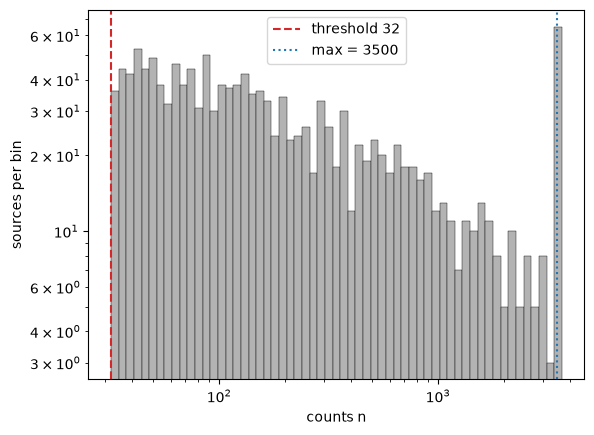

[[2.00000000e-02 9.24749913e-06 9.24749913e-06]
 [5.00000000e-02 7.56595369e-03 7.56595369e-03]
 [1.00000000e-01 4.53171407e-01 4.53171407e-01]
 [2.00000000e-01 9.99349794e-01 9.99349794e-01]
 [1.00000000e+00 1.00000000e+00 1.00000000e+00]]
p_det = 0.5 at F = 0.1029 F0 (ln F = -2.274)


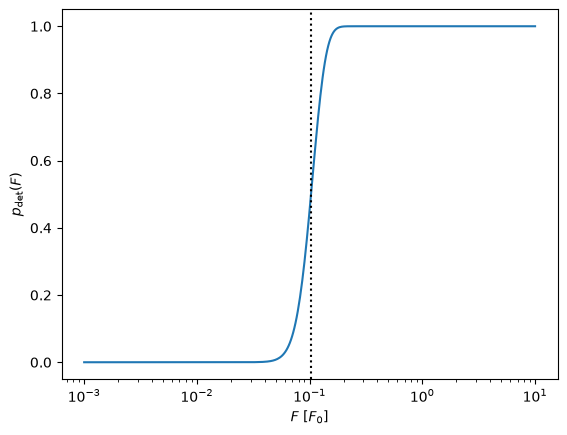

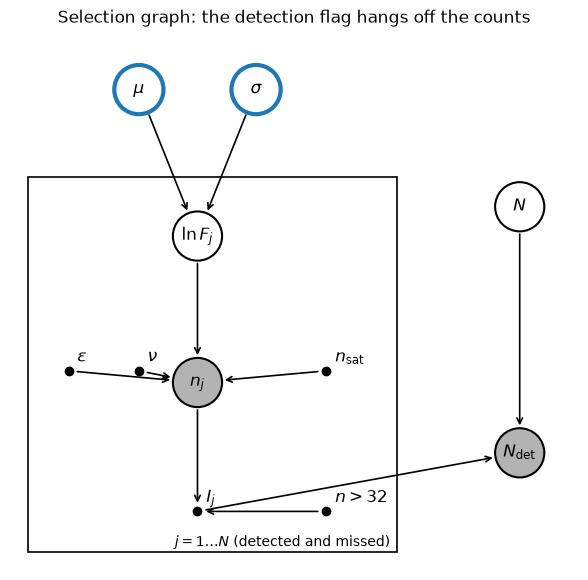

                                                   mu          sigma
saturation ignored, detector ignored   -0.280 ± 0.036  1.377 ± 0.025
saturation ignored, detector in          -1.25 ± 0.14  1.955 ± 0.077
saturation censored, detector ignored  -0.260 ± 0.037  1.429 ± 0.027
saturation censored, detector in         -1.62 ± 0.21    2.22 ± 0.11
dx = 0.01 : [-1.61904521  2.22196962] 
dx = 0.005: [-1.6190466   2.22197064]
f_det = 0.618 (16-84%: 0.578-0.659);  N_tot = 2428;  missed = 930 +160 / -150


In [7]:
from scipy.special import gammainc
n = pd.read_csv(LAB + f'{NETID}.csv')['n_counts'].to_numpy()
nu, eps, n_th = 9.373, 226.27, 32

def hessian(f, p, h=1e-4):  
    k = len(p); H = np.zeros((k, k))
    for i in range(k):
        for j in range(k):
            ei = np.zeros(k); ej = np.zeros(k); ei[i] = h; ej[j] = h
            H[i, j] = (f(p+ei+ej) - f(p+ei-ej) - f(p-ei+ej) + f(p-ei-ej)) / (4*h*h)
    return H

# 2.1 
S = int(n.max()); n_sat = int((n == S).sum())
vals, cts = np.unique(n, return_counts=True); top = np.argsort(cts)[::-1][:5]
print(f"max count {S}, {n_sat} sources exactly at the max; most repeated values: {list(zip(vals[top], cts[top]))}")
plt.hist(n, bins=np.logspace(np.log10(32), np.log10(S*1.05), 60), color='0.7', edgecolor='k', lw=0.3)
plt.axvline(n_th, color='C3', ls='--', label='threshold 32'); plt.axvline(S, color='C0', ls=':', label=f'max = {S}')
plt.xscale('log'); plt.yscale('log'); plt.xlabel('counts n'); plt.ylabel('sources per bin'); plt.legend(); plt.show()

# 2.2
lam_f = lambda F: eps*F + nu 
pdet = lambda F: gammainc(n_th + 1, lam_f(F)) 
Ft = np.array([0.02, 0.05, 0.1, 0.2, 1.0])
print(np.c_[Ft, pdet(Ft), stats.poisson.sf(n_th, lam_f(Ft))])  # the two columns must agree
F50 = brentq(lambda F: pdet(F) - 0.5, 1e-3, 10); print(f"p_det = 0.5 at F = {F50:.4f} F0 (ln F = {np.log(F50):.3f})")
Fg = np.logspace(-3, 1, 400); plt.semilogx(Fg, pdet(Fg)); plt.axvline(F50, ls=':', color='k')
plt.xlabel(r'$F$ [$F_0$]'); plt.ylabel(r'$p_{\rm det}(F)$'); plt.show()

nodesS = {'mu': (2, 8, r'$\mu$', 'param'), 'sig': (4, 8, r'$\sigma$', 'param'),
          'lnF': (3, 5.5, r'$\ln F_j$', 'latent'),
          'eps': (0.8, 3.2, r'$\epsilon$', 'fixed'), 'nu': (2.0, 3.2, r'$\nu$', 'fixed'),
          'n': (3, 3, r'$n_j$', 'data'), 'sat': (5.2, 3.2, r'$n_{\rm sat}$', 'fixed'),
          'I': (3, 0.8, r'$I_j$', 'fixed'), 'th': (5.2, 0.8, r'$n>32$', 'fixed'),
          'N': (8.5, 6, r'$N$', 'latent'), 'Ndet': (8.5, 1.8, r'$N_{\rm det}$', 'data')}
edgesS = [('mu', 'lnF'), ('sig', 'lnF'), ('lnF', 'n'), ('eps', 'n'), ('nu', 'n'), ('sat', 'n'),
          ('n', 'I'), ('th', 'I'), ('I', 'Ndet'), ('N', 'Ndet')]
draw_pgm(nodesS, edgesS, (0.1, 0.1, 6.3, 6.4, r'$j=1\ldots N$ (detected and missed)'),
         'Selection graph: the detection flag hangs off the counts', size=(9, 7))

# 2.3
def make_nll(nn, Sat=None, dx=0.01):
    lnF = np.arange(-14, 8 + dx/2, dx); lam = lam_f(np.exp(lnF))
    P = stats.poisson.pmf(nn[:, None], lam[None, :])
    if Sat is not None:   
        P[nn >= Sat] = stats.poisson.sf(Sat - 1, lam)[None, :]
    pd_grid = gammainc(n_th + 1, lam)
    def nll(p, detector=True):
        mu, sig = p
        if sig < 0.05 or sig > 6: return 1e30
        w = stats.norm.pdf(lnF, mu, sig)*dx
        out = -np.sum(np.log(np.maximum(P @ w, 1e-300)))
        if detector: out += len(nn)*np.log(pd_grid @ w)  
        return out
    return nll, lnF, pd_grid
def fit_ms(f, p0=(-0.5, 1.5)):
    r = minimize(f, p0, method='Nelder-Mead', options=dict(xatol=1e-7, fatol=1e-9, maxiter=2000))
    return r.x, np.linalg.inv(hessian(f, r.x, h=1e-3))  

res = {}
for fix in (False, True):
    nll_g, lnF, pd_grid = make_nll(n, S if fix else None)
    for det in (False, True):
        res[(fix, det)] = fit_ms(lambda p: nll_g(p, det))
tab = {f"saturation {'censored' if fix else 'ignored'}, detector {'in' if det else 'ignored'}":
       [fmt(r[0][0], np.sqrt(r[1][0, 0])), fmt(r[0][1], np.sqrt(r[1][1, 1]))] for (fix, det), r in res.items()}
print(pd.DataFrame(tab, index=['mu', 'sigma']).T)

nll_h, *_ = make_nll(n, S, dx=0.005) 
print('dx = 0.01 :', res[(True, True)][0], '\ndx = 0.005:', fit_ms(lambda p: nll_h(p, True))[0])

(mu_c, sig_c), cov_c = res[(True, True)]; (mu_n, sig_n), _ = res[(True, False)]
N_det = len(n); dx = 0.01
f_of = lambda m, s: pd_grid @ (stats.norm.pdf(lnF, m, s)*dx)
f_c = f_of(mu_c, sig_c); rng = np.random.default_rng(2)
ths = rng.multivariate_normal([mu_c, sig_c], cov_c, 4000); fs = np.array([f_of(m, s) for m, s in ths])
miss = N_det/fs - N_det; lo, md, hi = np.percentile(miss, [16, 50, 84])
print(f"f_det = {f_c:.3f} (16-84%: {np.percentile(fs, 16):.3f}-{np.percentile(fs, 84):.3f});  N_tot = {N_det/f_c:.0f};  missed = {fmt_asym(md, md-lo, hi-md)}")

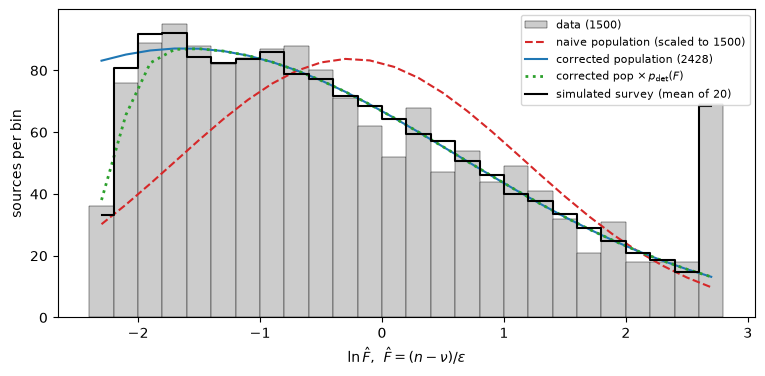

simulated survey keeps 1496 sources vs 1500 in the data


In [8]:
# 2.4
Fhat = (n - nu)/eps; lnFh = np.log(Fhat); bw = 0.2
edges = np.arange(np.floor(lnFh.min()/bw)*bw, lnFh.max() + bw, bw); ctr = 0.5*(edges[1:] + edges[:-1])
N_tot = N_det/f_c
naive = N_det*bw*stats.norm.pdf(ctr, mu_n, sig_n)
corr = N_tot*bw*stats.norm.pdf(ctr, mu_c, sig_c)
corr_det = corr*pdet(np.exp(ctr))
sims = []
for _ in range(20):
    lnF_s = rng.normal(mu_c, sig_c, int(round(N_tot)))
    n_s = np.minimum(rng.poisson(lam_f(np.exp(lnF_s))), S)
    k = n_s > n_th; sims.append(np.histogram(np.log((n_s[k] - nu)/eps), edges)[0])
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(lnFh, edges, color='0.8', edgecolor='k', lw=0.3, label=f'data ({N_det})')
ax.plot(ctr, naive, 'C3--', label='naive population (scaled to 1500)')
ax.plot(ctr, corr, 'C0-', label=f'corrected population ({N_tot:.0f})')
ax.plot(ctr, corr_det, 'C2:', lw=2, label=r'corrected pop $\times\, p_{\rm det}(F)$')
ax.step(ctr, np.mean(sims, 0), where='mid', color='k', lw=1.5, label='simulated survey (mean of 20)')
ax.set_xlabel(r'$\ln \hat F$,  $\hat F=(n-\nu)/\epsilon$'); ax.set_ylabel('sources per bin'); ax.legend(fontsize=8); plt.show()
print(f"simulated survey keeps {np.mean([s.sum() for s in sims]):.0f} sources vs {N_det} in the data")



**ANSWER (the two fits, f_det and the number missed, then the explanation):**

4% of the sources state that n = 3500, which is detector saturation so those counts are the measurement's lower limits. I kept them and censored them, using P(n ≥ 3500 | μ, σ) in place of the Poisson PMF, because dropping would need an upper truncation in p_det and discard the fact that these are the brightest sources. Censoring alone changes σ only slightly, but with the detector in it matters more, moving the fit from μ = −1.25 ± 0.14, σ = 1.955 ± 0.077 to μ = −1.62 ± 0.21, σ = 2.22 ± 0.11. The corrected fit gives f_det = 0.618 ± 0.04, so the survey missed about 930 (+160/−150) of roughly 2430 sources. Ignoring the detector biases μ high and σ low, because the missing faint sources push the mean up and remove one tail of the distribution, which makes the spread look smaller. \
The simulated survey from the corrected fit keeps 1504 sources against 1500 in the data and follows the histogram across the whole range, including the pile-up in the last bin from saturation. At the faint end the corrected population p_det does not match the histogram, because p_det acts on the true flux but the histogram is in F̂ = (n − ν)/ε.

## Part 3: A supernova in two dimensions (25%)

This one is real. The Carnegie Supernova Project (CSP-I) observed nearby Type Ia supernovae in six optical bands, from $u$ (364 nm) to $i$ (761 nm). Look up your supernova and your held-out band in `08/data/csp_assignments.csv`. Your light curve is `08/data/csp/<SN>.csv`, with columns `mjd`, `band`, `wavelength_A` (the band's effective wavelength), `flux_ujy` and `flux_err_ujy` (flux density in μJy), and the magnitudes they came from. The header gives the redshift and the date of maximum light in $B$. Data: Krisciunas et al. 2017, AJ 154, 211 (CC BY 4.0; credit the Carnegie Supernova Project).

Work in rest-frame phase, $(\mathrm{MJD} - T_{B\,\rm max})/(1+z)$, from $-10$ to $+40$ days, and divide every flux by the peak $B$ flux. Note that `V0`, `V1` and `V` are three versions of the same filter (within 32 Å) - treat them as one band, $V$.

A supernova's light curves in neighboring bands look alike, so a Gaussian process in **two** inputs, phase and wavelength, can learn all six at once and predict a band it never saw.

1. Plot every band against phase.
2. Fit a GP to the flux as a function of (phase, wavelength) using every band **except** your held-out one, with wavelength in microns (so both inputs are numbers of order 1-50). Use a kernel with its own length scale in phase and in wavelength (an anisotropic squared-exponential) times a fitted amplitude, each point's own measurement error, and a small white-noise term that you also fit. Fit the hyperparameters by maximizing the marginal likelihood (as in Lab 07), from more than one start. `sklearn`'s `GaussianProcessRegressor` (with `alpha` set to the squared errors, `normalize_y=False`, and `ConstantKernel` times `RBF` plus `WhiteKernel`) or your own Cholesky code from Lab 07 are both fine. Report the two length scales, and comment on what each means physically for a supernova.
3. Predict your held-out band at its epochs, with the GP's $1\sigma$ band, and plot it over the data. Report the rms residual as a fraction of the peak, and the fraction of held-out points within $1\sigma$ (add the GP's variance and the measurement variance). Does the GP's error bar look reasonable?
4. Now hold out $u$ instead, and report the same two numbers. Why is this so much harder? Think particularly about what the kernel assumes, and how far $u$ is from the other bands compared with your first held-out band.

In [9]:
# Part 3: your work here
asg = pd.read_csv(LAB + 'csp_assignments.csv')
SN, HOLD = asg.loc[asg.netid == NETID, ['sn', 'holdout_band']].iloc[0]
path = LAB + f'csp/{SN}.csv'
hdr = [l for l in open(path) if l.startswith('#')]  
z = float([l for l in hdr if 'z_helio' in l][0].split(':')[-1])
tmax = float([l for l in hdr if 'B-max MJD' in l][0].split(':')[1].split('+/-')[0])
d = pd.read_csv(path, comment='#')
d['band'] = d['band'].replace({'V0': 'V', 'V1': 'V'}) 
print(f'{SN}: z = {z}, B maximum at MJD {tmax}, {len(d)} points; held-out band: {HOLD}')

SN2004ey: z = 0.0158, B maximum at MJD 53303.73, 175 points; held-out band: r


['u', 'B', 'g', 'V', 'r', 'i'] held out: r


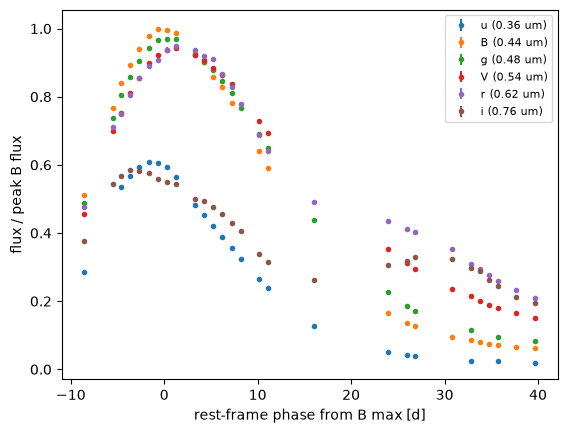

0.315**2 * RBF(length_scale=[7.94, 0.108]) + WhiteKernel(noise_level=2.68e-07)
amplitude  = 0.315 ± 0.045 (flux/peak B)
l_phase    = 7.94 ± 0.28 d
l_lambda   = 0.1075 ± 0.0084 um
white rms  = 0.00052 ± 0.00054 (flux/peak B)
[r held out, 28 points]  rms = 0.097 ± 0.013 of peak B flux;  within 1 sigma: 12/28 = 0.429 ± 0.088


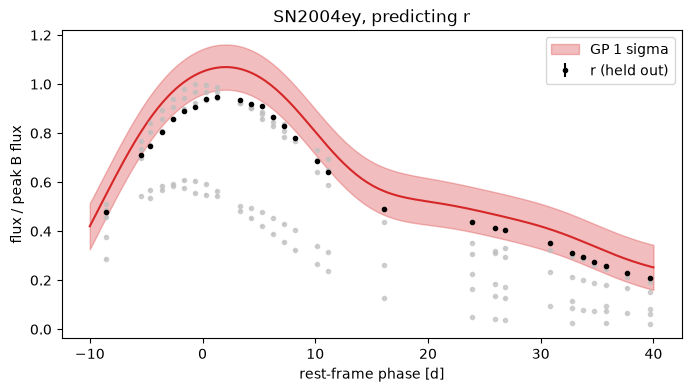

0.299**2 * RBF(length_scale=[7.76, 0.16]) + WhiteKernel(noise_level=4.22e-07)
amplitude  = 0.299 ± 0.044 (flux/peak B)
l_phase    = 7.76 ± 0.27 d
l_lambda   = 0.1595 ± 0.0097 um
white rms  = 0.00065 ± 0.00049 (flux/peak B)
[u held out, 23 points]  rms = 0.285 ± 0.042 of peak B flux;  within 1 sigma: 0/23 = 0.000 ± 0.050


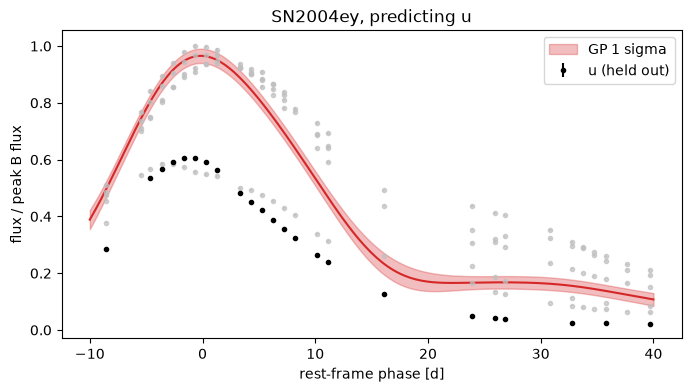

In [10]:
from sklearn.gaussian_process import GaussianProcessRegressor as GPR
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as CK, WhiteKernel

d = d.copy()
d['phase'] = (d['mjd'] - tmax)/(1 + z)
d = d[(d.phase >= -10) & (d.phase <= 40)].copy()
fpk = d.loc[d.band == 'B', 'flux_ujy'].max() 
d['f'], d['e'] = d.flux_ujy/fpk, d.flux_err_ujy/fpk
d['lam'] = d.groupby('band')['wavelength_A'].transform('mean')/1e4 
bands = d.groupby('band')['lam'].first().sort_values().index.tolist(); print(bands, 'held out:', HOLD)

# 3.1
for b in bands:
    s = d[d.band == b]; plt.errorbar(s.phase, s.f, s.e, fmt='.', capsize=0, label=f'{b} ({s.lam.iloc[0]:.2f} um)')
plt.xlabel('rest-frame phase from B max [d]'); plt.ylabel('flux / peak B flux'); plt.legend(fontsize=8); plt.show()

# 3.2 
def fit_gp(train, seed=0):
    k = CK(0.5, (1e-3, 1e2))*RBF([10.0, 0.3], [(1.0, 100.0), (0.02, 10.0)]) + WhiteKernel(1e-3, (1e-8, 1e-1))
    gp = GPR(k, alpha=train['e'].to_numpy()**2, normalize_y=False, n_restarts_optimizer=10, random_state=seed)
    return gp.fit(train[['phase', 'lam']].to_numpy(), train['f'].to_numpy())

def hyper_report(gp):
    th = gp.kernel_.theta
    H = hessian(lambda t: -gp.log_marginal_likelihood(t), th, h=1e-3)
    e = np.sqrt(np.clip(np.diag(np.linalg.inv(H)), 0, None)); v = np.exp(th)
    print(gp.kernel_)
    print(f"amplitude  = {fmt(np.sqrt(v[0]), np.sqrt(v[0])*e[0]/2, '(flux/peak B)')}\n"
          f"l_phase    = {fmt(v[1], v[1]*e[0+1], 'd')}\nl_lambda   = {fmt(v[2], v[2]*e[2], 'um')}\n"
          f"white rms  = {fmt(np.sqrt(v[3]), np.sqrt(v[3])*e[3]/2, '(flux/peak B)')}")
def fmt(v, e, unit=''):
    if not np.isfinite(e) or e <= 0:
        return f"{v:.3g} {unit}".strip()
    d = 1 - int(np.floor(np.log10(abs(e))))
    return f"{round(v, d):.{max(d, 0)}f} ± {round(e, d):.{max(d, 0)}f} {unit}".strip()

def frac_err(k, nt):
    """Fraction k/nt with an error bar that stays nonzero at 0 or 1 (Agresti-Coull)."""
    p = (k + 2) / (nt + 4)
    return k / nt, np.sqrt(p * (1 - p) / (nt + 4))

# 3.3 / 3.4 hold out one band, predict it, score it
def holdout(band, seed=0):
    tr, te = d[d.band != band], d[d.band == band]
    gp = fit_gp(tr, seed); hyper_report(gp)
    mu_p, sd = gp.predict(te[['phase', 'lam']].to_numpy(), return_std=True)
    r = te['f'].to_numpy() - mu_p; tot = np.sqrt(sd**2 + te['e'].to_numpy()**2)
    rms = np.sqrt(np.mean(r**2)); nt = len(te)
    k_in = int(np.sum(np.abs(r) < tot)); inside, inside_err = frac_err(k_in, nt)
    print(f"[{band} held out, {nt} points]  rms = {fmt(rms, rms/np.sqrt(2*nt), 'of peak B flux')};  "
          f"within 1 sigma: {k_in}/{nt} = {fmt(inside, inside_err)}")
    tg = np.linspace(-10, 40, 200); mg, sg = gp.predict(np.c_[tg, np.full(200, te.lam.iloc[0])], return_std=True)
    fig, ax = plt.subplots(figsize=(8, 4))
    for b in bands:
        if b != band: s = d[d.band == b]; ax.errorbar(s.phase, s.f, s.e, fmt='.', color='0.75', alpha=0.7)
    ax.errorbar(te.phase, te.f, te.e, fmt='ko', ms=3, label=f'{band} (held out)')
    ax.plot(tg, mg, 'C3'); ax.fill_between(tg, mg - sg, mg + sg, color='C3', alpha=0.3, label='GP 1 sigma')
    ax.set_xlabel('rest-frame phase [d]'); ax.set_ylabel('flux / peak B flux'); ax.set_title(f'{SN}, predicting {band}'); ax.legend(); plt.show()
for b in dict.fromkeys([HOLD, 'u']): 
    holdout(b)

**ANSWER (length scales, the two held-out tests, then why u is harder):**

The GP gives l_phase = 7.9 ± 0.3d, comparable to the rise, decline and shoulder timescale of a SN Ia light curve. We also see that ℓ_λ = 0.108 ± 0.008 µm, which is about the spacing of neighbouring bands so light curves decorrelate over one band as the spectrum's features change with wavelength. Holding out r, the RMS residual is 0.097 ± 0.013 of the peak B flux, but only 12/28 = 0.43 ± 0.09 points lie within 1 standard deviation, so the error bar is too small. The prediction is about 0.1 too high near peak, and the fitted white noise leaves no room for mismatch. Holding out u is much worse, with a RMS of 0.285 ± 0.042 and no data points within one standard deviation because the prediction follows a B-like curve and peaks near 1.0 while u actually peaks near 0.6. u sits at the edge of the wavelength range, so predicting it is extrapolation rather than interpolation since the stationary, zero-mean RBF kernel can only copy the nearest bands. It has no way to represent the systematic fall of UV flux below the optical from line blanketing, so its narrow ±0.03 band is confidently wrong.

## Part 4: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 1 and Part 2 numbers, and what failure would have looked like for each. Part 1.3 is already one. For Part 2, one check to consider is to simulate a catalog yourself with a $\mu$ and $\sigma$ you choose, through the same detector, run both fits on it, and see whether the corrected fit gets back what you put in and the naive one doesn't. One catalog isn't enough - comment on how many you'd need.

**AI-USE APPENDIX:**

As with previous labs, I used Claude's Sonnet 5.5 AI to generate some boilerplate code for this lab, particularly for the more mathematical helper functions (and with visual diagram generation) where there were additional parameters and syntax I wanted to check on. Claude also contributed to make the graphs cleaner for the data they could show and helped format the fstring outputs to be more readable. In this lab especially, Claude helped me clean up a number of my graphs since there were many visualizations needed here, and the diagram helpers made them much easier to generate. 
If you notice that this appendix is very similar to the ones submitted on the previous labs, that is a choice made intentionally, since AI was used the same way on these labs.

**REFLECTION:**

Treating the 60 sources at n = 3500 as real counts would have biased σ and the number of missed sources, and the “simulated survey” would not have matched the bright end. If I had treated them as exact counts, the likelihood would have asked the population to explain 60 sources at one precise flux. The model would have been fitting a cut-off bright tail as if it were real, and the bright tail is what constrains σ. The fit would have underestimated the width, and the damage shows in the numbers. With the detector in, ignoring saturation gives σ = 1.955 ± 0.077 and μ = −1.25 ± 0.14, against σ = 2.22 ± 0.11 and μ = −1.62 ± 0.21 with censoring. These differ by about 2σ in σ and about 1.5σ in μ, and both are well outside the 1e-6 grid-convergence noise.

**VERIFICATION PLAN:**

In Part 1, I maximized the Gaussian marginal likelihood and compared it with the PyMC medians. If these had disagreed by more than 1 standard deviation, I would have known there was an error in the 3x3 covariance matrix. Their agreement gave me reason to believe both of their results. In part 2, I made sure that `gammainc(33, λ)` agrees with `poisson.sf(32, λ)` to all printed digits at five fluxes, so the threshold is not off by one. In part 3, I scored the predictions with the fraction within 1 standard deviation as well as the rms. Failure would be a coverage far from 68%, but I got 0.43 for r and 0.00 for u.